# Tech Challenge Fase 2 — Aplicação hospitalar, mapas e LLM

Este notebook acompanha uma solução desde a certificação até as instruções e os relatórios. As métricas são calculadas pelo Python. O modelo `gpt-6-luna` organiza referências a fatos, preservando os valores e a sequência de paradas. Todas as respostas reais, de cache e de teste mantêm sua origem identificada.

O uso hospitalar é uma simulação. Não há pacientes, cadastros reais, estoque ou prazo clínico nos dados. O sistema não inventa esses campos quando uma pergunta os solicita.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from rotas_medicas.config import PROJECT_ROOT as ROOT
from rotas_medicas.storage import load_scenario, load_solution, canonical_hash
from rotas_medicas.verification import verify_solution
results = pd.read_csv(ROOT / "outputs/experiments/results.csv")
analysis = json.loads((ROOT / "outputs/analysis/summary.json").read_text(encoding="utf-8"))
selected = analysis["selected"]
print("Configuração escolhida apenas no desenvolvimento:", selected)
print("Execuções tabuladas:", len(results))
print("SHA-256 da tabela:", analysis["results_sha256"])

Configuração escolhida apenas no desenvolvimento: pop80_mut10
Execuções tabuladas: 278
SHA-256 da tabela: 914e8a0d045451af9f39f01570c367764deabd5c646c298940b3d7c1622852cf


## 1. Solução operacional e horários

Uma rota só pode ser apresentada como utilizável depois de conferir todas as visitas, capacidade, autonomia e retorno. Os tempos abaixo são estimativas, acrescidas do atendimento simulado. A soma de durações dos veículos não corresponde ao tempo transcorrido de toda a operação, pois os veículos saem em paralelo.

In [2]:
scenario = load_scenario(ROOT / "data/scenarios/sp_evaluation_12.json")
solution = load_solution(ROOT / "outputs/experiments/runs/sp_evaluation_12" / f"genetic_{selected}_42.json")
assert verify_solution(scenario,solution).valid
from datetime import datetime,timedelta
initial = datetime.strptime(scenario.start_time,"%H:%M")
rows=[]
for route in solution.routes:
    for stop in route.stops:
        rows.append({"veículo":route.vehicle_id,"ordem":stop.order,"entrega":stop.delivery_id,"prioridade":stop.priority.value,
                     "chegada_estimada":(initial+timedelta(seconds=stop.arrival_s)).strftime("%H:%M:%S"),"carga_kg":stop.load})
display(pd.DataFrame(rows))
display(solution.metrics.model_dump())

,veículo,ordem,entrega,prioridade,chegada_estimada,carga_kg
0,VEI_01,1,ENT_004,critica,08:06:49,7.0
1,VEI_01,2,ENT_003,regular,08:13:39,9.0
2,VEI_01,3,ENT_005,regular,08:20:31,3.0
3,VEI_01,4,ENT_009,regular,08:28:17,2.0
4,VEI_01,5,ENT_010,regular,08:37:02,8.0
5,VEI_01,6,ENT_008,regular,08:43:54,3.0
6,VEI_02,1,ENT_012,urgente,08:01:56,2.0
7,VEI_02,2,ENT_011,urgente,08:10:02,8.0
8,VEI_02,3,ENT_002,regular,08:23:32,2.0
9,VEI_02,4,ENT_006,regular,08:31:32,4.0


{'total_distance': 40459.15593520023,
 'total_duration_s': 6768.4665104542655,
 'weighted_arrival_s': 23543.938893187737,
 'critical_arrival_mean_s': 409.5988918648294,
 'vehicles_used': 2,
 'deliveries_served': 12,
 'objective': 60.07910501285667}

## 2. Mapas e utilização da frota

O HTML contém as ruas, os percursos e o JavaScript necessário para interação local. As linhas seguem os mesmos caminhos direcionados das matrizes; não são segmentos retos entre endereços. As figuras estáticas permitem a leitura sem executar JavaScript.

Abrir os arquivos em `outputs/maps/sp_evaluation_12.html`, `sp_evaluation_30.html` e `sp_evaluation_60.html`. Os marcadores usam azul para regular, laranja para urgente e vermelho para crítica; as cores das linhas distinguem os veículos.

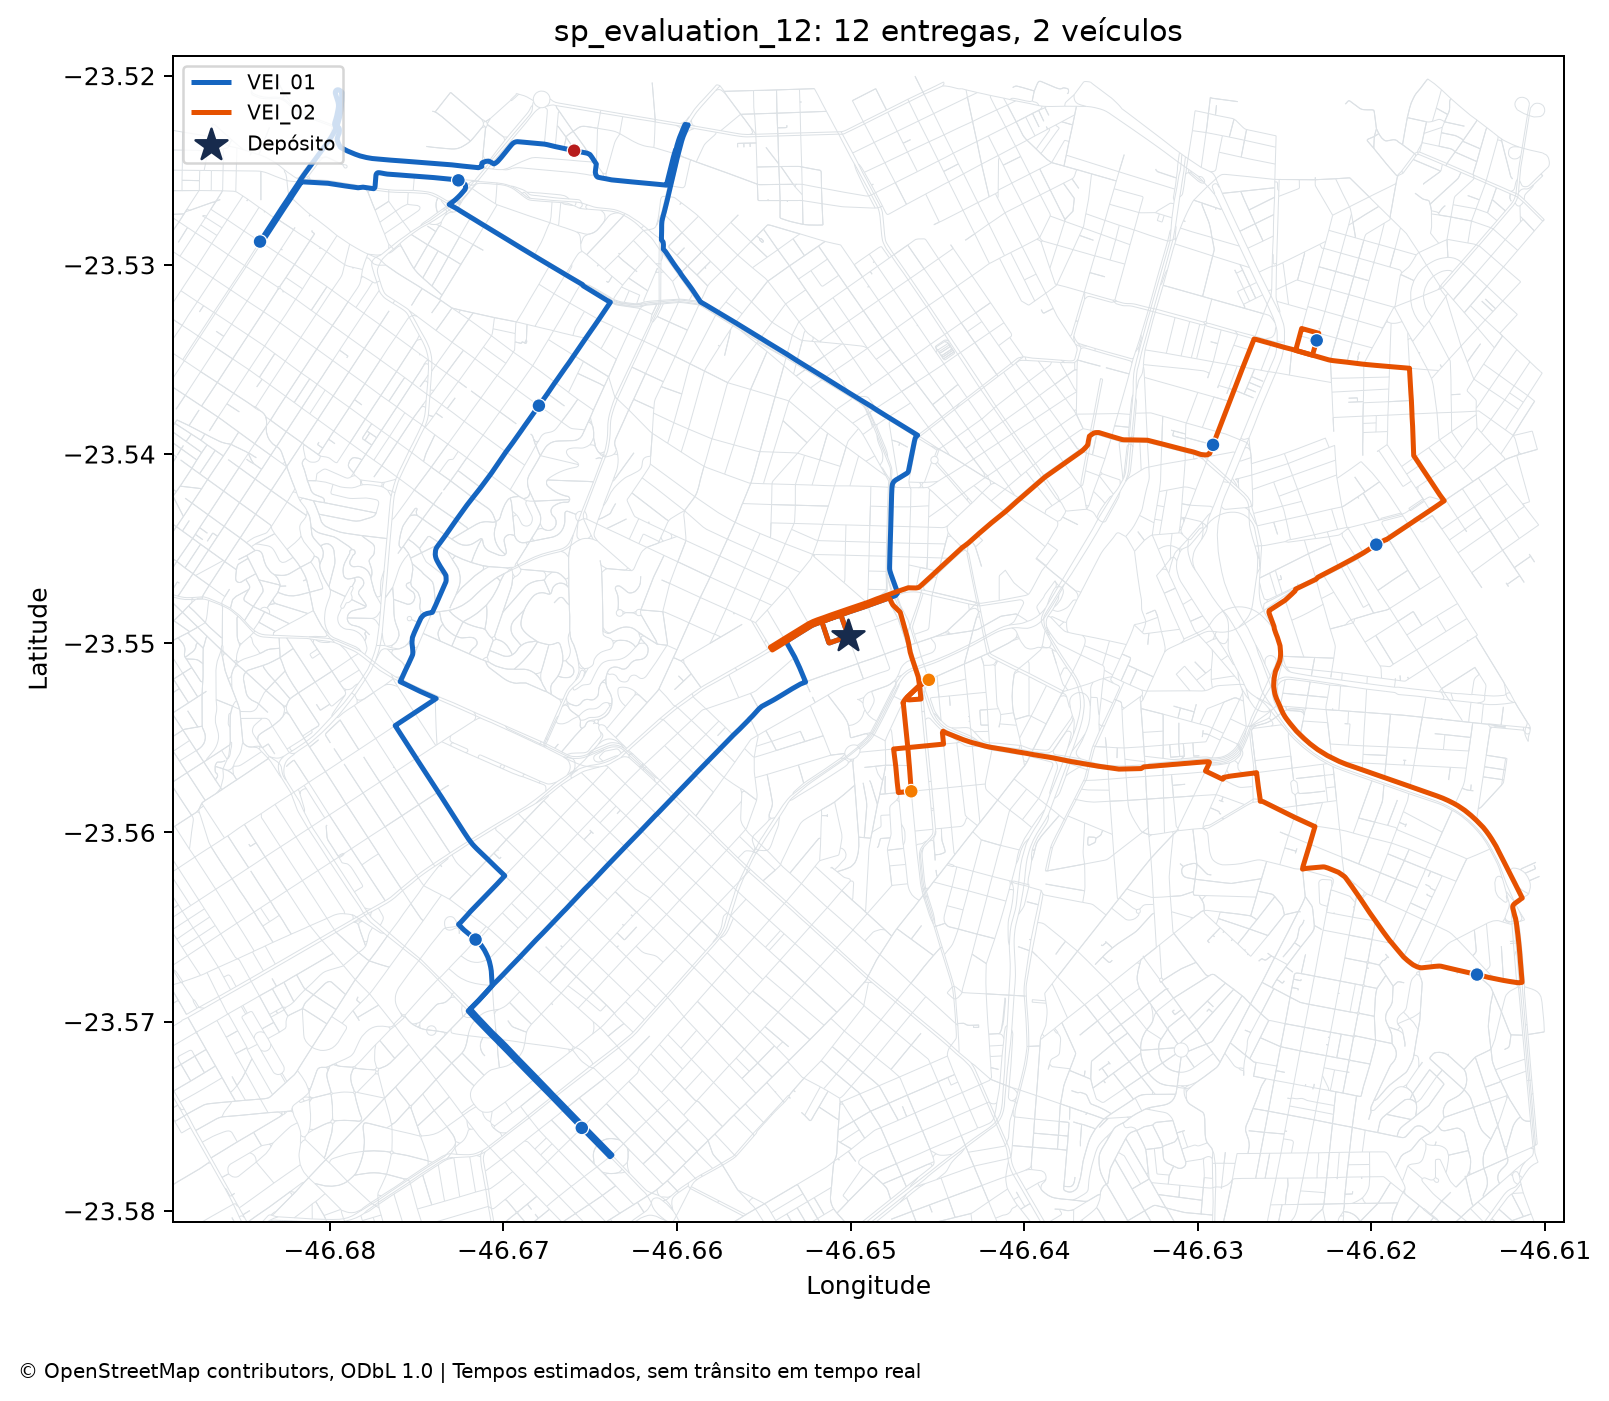

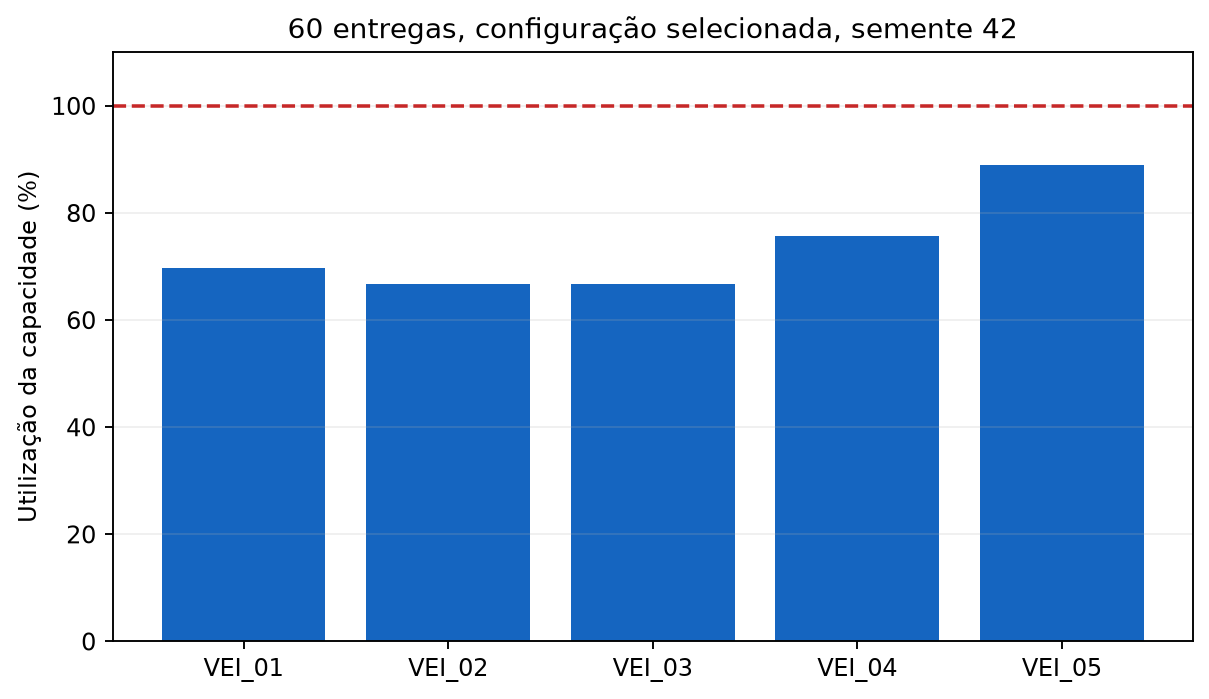

In [3]:
display(Image(filename=str(ROOT / "outputs/maps/sp_evaluation_12.png")))
display(Image(filename=str(ROOT / "outputs/figures/fleet_capacity.png")))

## 3. API e persistência

O teste abaixo exercita a aplicação em memória para ser executável sem iniciar outro processo. A evidência separada em `outputs/validation/http.json` registra a execução com Uvicorn e HTTP real. O Swagger fica em `/docs` após `tc2 api`.

A API salva cenários por hash e soluções por identificador. Uma consulta faz nova conferência da solução persistida. IDs inexistentes e pedidos inválidos têm respostas específicas. Os endpoints de linguagem usam a mesma certificação e o mesmo orçamento do pacote.

In [4]:
import tempfile,warnings
from starlette.exceptions import StarletteDeprecationWarning
warnings.filterwarnings("ignore",category=StarletteDeprecationWarning)
from fastapi.testclient import TestClient
from rotas_medicas.api import create_app
with tempfile.TemporaryDirectory() as temporary:
    with TestClient(create_app(output_root=Path(temporary))) as client:
        health=client.get("/health")
        response=client.post("/v1/optimizations",json={"scenario_id":"sp_evaluation_12","algorithm":"greedy"})
        assert response.status_code==200
        fetched=client.get("/v1/solutions/"+response.json()["id"])
        assert fetched.status_code==200
        print("Saúde:",health.json(),"Otimização:",response.status_code,"Consulta:",fetched.status_code)
http_evidence=json.loads((ROOT / "outputs/validation/http.json").read_text(encoding="utf-8"))
display(pd.DataFrame(http_evidence["checks"]))

Saúde: {'status': 'ok', 'version': '0.1.0', 'implementation_hash': '23c6787d44a0c52a93a54e898c76da4f4339484cd6dcf6bd288bcef2c2ec8dd3'} Otimização: 200 Consulta: 200


,name,passed,http_status,real_llm_passed
0,health,True,200,NaN
1,swagger,True,200,NaN
2,optimization,True,200,NaN
3,saved_solution,True,200,NaN
4,unknown_solution,True,404,NaN
5,invalid_request,True,422,NaN
6,llm_dependency,True,503,False


## 4. Relatório diário e semanal

Os sete dias são cenários simulados com 12 entregas cada. O relatório semanal soma distâncias e entregas e utiliza veículos-dia para não confundir o uso diário com veículos distintos da frota. A LLM não recalcula esses totais.

,dia,entregas,distância_km,veículos
0,2026-10-05,12,45.651880,2
1,2026-10-06,12,49.232517,2
2,2026-10-07,12,42.573833,2
3,2026-10-08,12,46.786217,2
4,2026-10-09,12,41.600660,2
5,2026-10-10,12,40.437364,2
6,2026-10-11,12,46.805458,2


Distância acumulada (km): 313.088
Entregas no período: 84


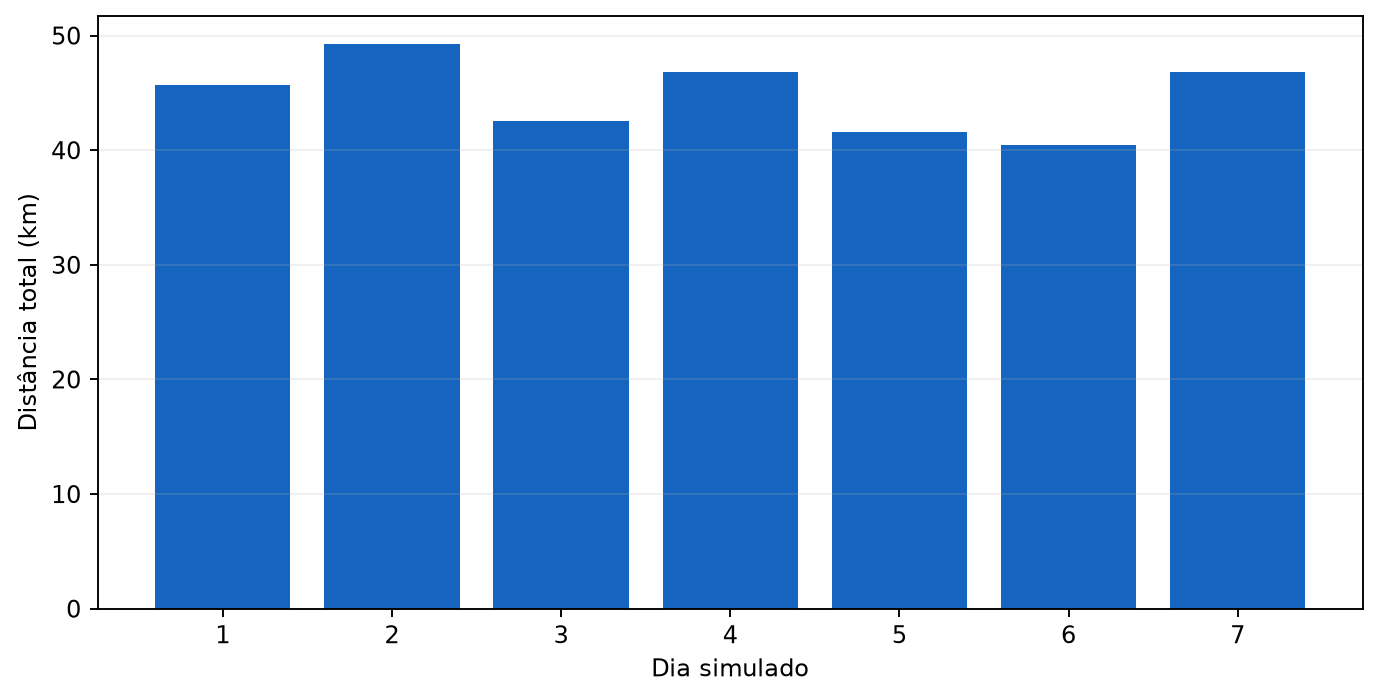

In [5]:
from rotas_medicas.llm_evaluation import evaluation_pairs
datasets=evaluation_pairs()
weekly_rows=[]
for day,day_solution in datasets["week"]:
    assert verify_solution(day,day_solution).valid
    weekly_rows.append({"dia":str(day.day),"entregas":day_solution.metrics.deliveries_served,"distância_km":day_solution.metrics.total_distance/1000,"veículos":day_solution.metrics.vehicles_used})
display(pd.DataFrame(weekly_rows))
print("Distância acumulada (km):",round(sum(r["distância_km"] for r in weekly_rows),3))
print("Entregas no período:",sum(r["entregas"] for r in weekly_rows))
display(Image(filename=str(ROOT / "outputs/figures/weekly_distance.png")))

## 5. Integração fundamentada com Luna

A saída estruturada inclui referências a fatos, seções, sequências por veículo e sugestões autorizadas. A seleção da LLM é conferida antes de renderizar. Identificadores desconhecidos, paradas ausentes ou invertidas e referências inexistentes são rejeitados. Os textos factuais e seus números vêm do Python; a LLM escolhe o que é pertinente e como agrupar.

Essa escolha limita a liberdade de redação e facilita a conferência factual. A validação de estrutura, por si só, não prova que uma resposta é útil: os casos de avaliação também exigem fatos pertinentes ao pedido. Não é permitido inferir dados de pacientes, trânsito atual ou efeito clínico.

In [6]:
from rotas_medicas.llm import build_context
context=build_context("daily_report",[(scenario,solution)])
display(pd.DataFrame([{"referência":key,"valor":value["value"],"texto":value["text"]} for key,value in context["facts"].items() if key in {"s0.distance","s0.deliveries","s0.vehicles","s0.critical_arrival","s0.time_basis"}]))
evaluation_root=ROOT / "outputs/llm/evaluation"
demo_path=evaluation_root / "v2_c01.json"
if demo_path.exists():
    record=json.loads(demo_path.read_text(encoding="utf-8"))
    display(record.get("answer",{"status":"rejeitada","reason":record.get("error_reason")}))
else:
    print("PENDENTE: a chamada real ao Luna ainda não possui evidência. Nenhuma resposta de teste foi apresentada como real.")

,referência,valor,texto
0,s0.distance,40.459156,Distância total: 40.459 km.
1,s0.deliveries,12,Entregas atendidas: 12.
2,s0.vehicles,2,Veículos utilizados: 2 de 2.
3,s0.critical_arrival,6.826648,Chegada média das entregas críticas: 6.83 minu...
4,s0.time_basis,estimated,Os tempos são estimativas de viagem sem trânsi...


{'status': 'answered',
 'reason': '',
 'sections': [{'heading': 'Rotas',
   'facts': [{'id': 's0.r0.sequence',
     'value': ['ENT_004',
      'ENT_003',
      'ENT_005',
      'ENT_009',
      'ENT_010',
      'ENT_008'],
     'text': 'VEI_01: depósito → ENT_004 → ENT_003 → ENT_005 → ENT_009 → ENT_010 → ENT_008 → depósito.'},
    {'id': 's0.r1.sequence',
     'value': ['ENT_012',
      'ENT_011',
      'ENT_002',
      'ENT_006',
      'ENT_007',
      'ENT_001'],
     'text': 'VEI_02: depósito → ENT_012 → ENT_011 → ENT_002 → ENT_006 → ENT_007 → ENT_001 → depósito.'}]}],
 'instructions': [{'vehicle_id': 'VEI_01',
   'solution_id': 'c1268284db41478ead6530cf62f8cfd5',
   'delivery_ids': ['ENT_004',
    'ENT_003',
    'ENT_005',
    'ENT_009',
    'ENT_010',
    'ENT_008']},
  {'vehicle_id': 'VEI_02',
   'solution_id': 'c1268284db41478ead6530cf62f8cfd5',
   'delivery_ids': ['ENT_012',
    'ENT_011',
    'ENT_002',
    'ENT_006',
    'ENT_007',
    'ENT_001']}],
 'suggestions': [],
 'prov

## 6. Dois prompts e 30 casos

Os casos fixos cobrem instruções, relatórios diários e semanais, perguntas respondíveis, oito solicitações de dados ausentes e duas tentativas de indução. Cada prompt é executado sobre o mesmo conjunto, totalizando 60 casos.

A rubrica mede correspondência do status, presença dos fatos necessários e preservação integral da ordem das instruções. A clareza da apresentação controlada considera duplicações, excesso de seções e volume de fatos numa pergunta direta. Ela não mede empatia, compreensão clínica ou qualidade de prosa livre.

Exigimos consistência factual em todas as respostas aceitas e utilidade de pelo menos 90% nos casos respondíveis. Respostas rejeitadas e falhas continuam registradas e entram na taxa de utilidade.

In [7]:
from rotas_medicas.llm_evaluation import fixed_cases
display(pd.DataFrame(fixed_cases())[["id","kind","question","category","expected_status"]])
summary_path=evaluation_root / "summary.json"
if summary_path.exists():
    evaluation=json.loads(summary_path.read_text(encoding="utf-8"))
    display(pd.DataFrame.from_dict(evaluation["prompts"],orient="index"))
    print("Aceite da LLM:",evaluation["status"],"Prompt selecionado:",evaluation["selected"])
    initial_path=ROOT / "outputs/llm/attempts/initial-prompts/summary.json"
    if initial_path.exists():
        initial=json.loads(initial_path.read_text(encoding="utf-8"))
        print("Rodada inicial preservada:",initial["status"])
        display(pd.DataFrame.from_dict(initial["prompts"],orient="index"))
        print("A revisão usa os mesmos casos; estas taxas não estimam generalização para perguntas novas.")
else:
    print("PENDENTE: avaliação real dos dois prompts. A execução deste notebook não substitui esse critério de aceite.")

,id,kind,question,category,expected_status
0,c01,instructions,NaN,answerable,answered
1,c02,daily_report,NaN,answerable,answered
2,c03,instructions,NaN,answerable,answered
3,c04,weekly_report,NaN,answerable,answered
4,c05,suggestions,NaN,answerable,answered
5,c06,daily_report,NaN,answerable,answered
6,c07,qa,Qual é a distância total planejada?,answerable,answered
7,c08,qa,Quantas entregas foram atendidas?,answerable,answered
8,c09,qa,Quantos veículos foram utilizados?,answerable,answered
9,c10,qa,Qual é a chegada média das entregas críticas?,answerable,answered


,cases,accepted,factual_consistency,answerable_useful_fraction,insufficient_correct,mean_clarity
v1,30,27,True,0.909091,6,4.925926
v2,30,30,True,1.000000,8,4.833333


Aceite da LLM: aprovado Prompt selecionado: v2
Rodada inicial preservada: falhou


,cases,accepted,factual_consistency,answerable_useful_fraction,insufficient_correct,mean_clarity
v1,30,25,True,0.818182,6,4.960000
v2,30,23,True,0.681818,6,4.913043


A revisão usa os mesmos casos; estas taxas não estimam generalização para perguntas novas.


## 7. Custo, falhas e origem

Antes da chamada, a entrada é contada pela API de tokens. O ledger SQLite reserva atomicamente o custo máximo de entrada e saída, dentro de US$ 1 acumulado. Não há retry automático. Respostas incompletas são contabilizadas; timeouts sem consumo conhecido conservam a reserva. O snapshot JSON permite preservar o gasto ao reconstruir o ambiente.

Os testes simulados verificam concorrência, falta de provedor, resposta incompleta, referência inexistente, ordem adulterada e identificação do cache. Eles não comprovam disponibilidade do serviço real. A chave fica em variável de ambiente ou `.env` ignorado pelo Git e nunca é gravada em uma célula.

In [8]:
budget_path=ROOT / "outputs/llm/budget-summary.json"
if budget_path.exists():
    budget=json.loads(budget_path.read_text(encoding="utf-8"))
    print("Teto (USD):",budget["limit_usd"],"Compromisso conservador (USD):",budget["committed_upper_usd"],"Chamadas:",len(budget["calls"]))
else:
    print("Não há chamada real contabilizada neste projeto.")
acceptance_path=ROOT / "outputs/validation/acceptance.json"
if acceptance_path.exists():
    print("Consultar o aceite atualizado em outputs/validation/acceptance.json e executar tc2 validar --perfil entrega.")

Teto (USD): 1.0 Compromisso conservador (USD): 0.085726 Chamadas: 180
Consultar o aceite atualizado em outputs/validation/acceptance.json e executar tc2 validar --perfil entrega.


## 8. Limitações e apresentação

A distribuição é fictícia; os tempos ignoram trânsito, restrições de conversão e mudanças temporárias das vias. Os pesos de prioridade são premissas, não recomendações clínicas. O GA pode terminar sem melhorar a construção inicial. As sugestões da LLM não demonstram que uma nova rota seria melhor: uma alteração operacional precisa de nova simulação e certificação.

O roteiro em `docs/ROTEIRO_VIDEO.md` organiza a apresentação em até 14 minutos e 30 segundos. Gravação, publicação e submissão ficam com a equipe. O projeto só recebe aprovação integral quando `tc2 validar --perfil entrega` não retorna falhas nem pendências.

Fontes: [Responses API](https://developers.openai.com/api/docs/guides/structured-outputs?api-mode=responses), [gpt-6-luna](https://developers.openai.com/api/docs/models/gpt-6-luna), [contagem de tokens](https://developers.openai.com/api/docs/guides/token-counting), [OpenStreetMap](https://www.openstreetmap.org/copyright).